# Práctica 4 - Detección y Seguimiento Persistente de Personas

Este cuaderno aborda de forma específica e independiente el **primer requisito** de la práctica: **detectar y seguir a las personas presentes mediante tracking persistente**.

### Aspectos clave incluidos:
- **Detección con YOLO11** (`yolo11n.pt`) filtrando estrictamente la clase `person` (clase 0 en COCO).
- **Seguimiento persistente (Tracking)** con **BoT-SORT** (`persist=True`), conservando el mismo identificador numérico (`track_id`) para cada persona a lo largo de la secuencia.
- **Visualización de trayectorias (estela)**: trazado del recorrido temporal continuo a partir de la posición de la base de cada individuo.
- **HUD informativo en vivo**: monitorización del fotograma actual, número de personas activas en pantalla y conteo acumulado de individuos únicos.
- **Exportación de vídeo**: generación del fichero de vídeo resultante (`resultado_tracking_personas.mp4`) con todas las anotaciones superpuestas.

In [1]:
# Importación de librerías esenciales
import os
import cv2
import numpy as np
from collections import defaultdict
from ultralytics import YOLO
import matplotlib.pyplot as plt

In [2]:
# 1. Parámetros de configuración
MODEL_NAME = "yolo11n.pt"                      # Modelo YOLO11 (nano para máxima fluidez)
VIDEO_PATH = "TGC23_PdH_C0056cut.mp4"            # Vídeo de entrada
OUTPUT_VIDEO = "resultado_tracking_personas.mp4" # Vídeo anotado de salida

CLASSES_TRACK = [0]                           # 0: person en el estándar COCO
CONF_THRES = 0.3                              # Umbral de confianza de detección
TRACKER_CONFIG = "botsort.yaml"                # Algoritmo de tracking ("botsort.yaml" o "bytetrack.yaml")
MAX_TRAIL_LEN = 35                            # Longitud máxima de la estela de trayectoria

# Inicialización del modelo (descarga automática si no estuviera en local)
model = YOLO(MODEL_NAME)
print(f"Modelo '{MODEL_NAME}' preparado correctamente.")

Modelo 'yolo11n.pt' preparado correctamente.


In [3]:
# 2. Función de procesamiento y seguimiento persistente
def procesar_tracking_personas(video_path, output_path=None, mostrar_en_vivo=False):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir el vídeo: {video_path}")
        
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    writer = None
    if output_path:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        writer = cv2.VideoWriter(output_path, fourcc, fps, (w, h))
        
    # Buffer de trayectorias por cada track_id
    track_history = defaultdict(lambda: [])
    # Conjunto para registrar todos los individuos únicos rastreados
    personas_unicas = set()
    
    print(f"Iniciando tracking persistente en '{video_path}'...")
    print(f"Resolución: {w}x{h} | FPS: {fps:.2f} | Fotogramas totales: {total_frames}")
    
    frame_idx = 0
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
            
        frame_idx += 1
        
        # Detección y actualización de tracking persistente entre fotogramas sucesivos
        results = model.track(
            frame,
            persist=True,
            classes=CLASSES_TRACK,
            conf=CONF_THRES,
            tracker=TRACKER_CONFIG,
            verbose=False
        )
        
        personas_activas = 0
        
        if results[0].boxes is not None and results[0].boxes.id is not None:
            boxes = results[0].boxes.xyxy.cpu().numpy()
            track_ids = results[0].boxes.id.int().cpu().tolist()
            confidences = results[0].boxes.conf.cpu().numpy()
            
            personas_activas = len(track_ids)
            
            for box, track_id, conf in zip(boxes, track_ids, confidences):
                personas_unicas.add(track_id)
                x1, y1, x2, y2 = box.astype(int)
                
                # Punto inferior central (contacto con el suelo) para la trayectoria
                cx = int((x1 + x2) / 2)
                cy = int(y2)
                track_history[track_id].append((cx, cy))
                if len(track_history[track_id]) > MAX_TRAIL_LEN:
                    track_history[track_id].pop(0)
                    
                # Asignación de color consistente y distintivo para cada ID
                np.random.seed(int(track_id) * 37 + 11)
                color = tuple(int(c) for c in np.random.randint(60, 255, 3).tolist())
                
                # 1. Bounding Box
                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
                
                # 2. Etiqueta con Track ID y confianza
                label = f"Persona ID {track_id} ({conf:.2f})"
                (lw, lh), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
                top_y = max(lh + 6, y1)
                cv2.rectangle(frame, (x1, top_y - lh - 6), (x1 + lw + 6, top_y), color, -1)
                cv2.putText(frame, label, (x1 + 3, top_y - 4), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)
                
                # 3. Estela de trayectoria continua
                puntos = np.array(track_history[track_id], dtype=np.int32).reshape((-1, 1, 2))
                cv2.polylines(frame, [puntos], isClosed=False, color=color, thickness=3, lineType=cv2.LINE_AA)
                cv2.circle(frame, (cx, cy), 4, color, -1)
        
        # 4. HUD superior con métricas del fotograma
        hud_text = f"Frame: {frame_idx:03d}/{total_frames} | Personas activas: {personas_activas} | Total unicos: {len(personas_unicas)}"
        cv2.rectangle(frame, (10, 10), (620, 48), (20, 20, 20), -1)
        cv2.rectangle(frame, (10, 10), (620, 48), (0, 200, 255), 1)
        cv2.putText(frame, hud_text, (20, 36), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2, cv2.LINE_AA)
        
        if writer:
            writer.write(frame)
            
        if mostrar_en_vivo:
            cv2.imshow("YOLO11 Tracking Persistente de Personas", frame)
            if cv2.waitKey(1) & 0xFF in (27, ord("q")):
                print("Interrumpido por el usuario.")
                break
                
    cap.release()
    if writer:
        writer.release()
    cv2.destroyAllWindows()
    
    print("\n=== RESUMEN DEL SEGUIMIENTO ===")
    print(f"Fotogramas procesados: {frame_idx}")
    print(f"Identificadores de personas rastreados: {sorted(list(personas_unicas))}")
    print(f"Total de personas unicas detectadas: {len(personas_unicas)}")
    if output_path and os.path.exists(output_path):
        print(f"Vídeo resultante generado en: {output_path}")
        
    return sorted(list(personas_unicas))

In [4]:
# 3. Ejecución del pipeline sobre el vídeo
# (Si ejecutas localmente y deseas ver la ventana de OpenCV en vivo, cambia mostrar_en_vivo=True)
ids_detectados = procesar_tracking_personas(
    video_path=VIDEO_PATH,
    output_path=OUTPUT_VIDEO,
    mostrar_en_vivo=False
)

Iniciando tracking persistente en 'TGC23_PdH_C0056cut.mp4'...
Resolución: 1280x720 | FPS: 25.00 | Fotogramas totales: 375

=== RESUMEN DEL SEGUIMIENTO ===
Fotogramas procesados: 375
Identificadores de personas rastreados: [1, 2, 3, 6, 7, 8, 9, 10, 12, 21, 23]
Total de personas unicas detectadas: 11
Vídeo resultante generado en: resultado_tracking_personas.mp4


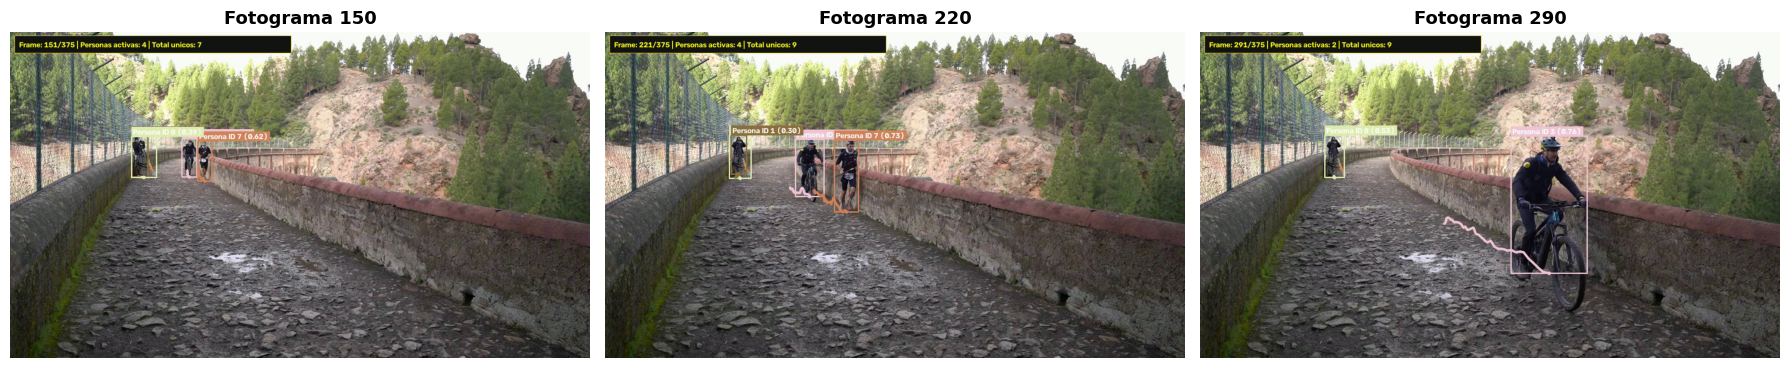

In [5]:
# 4. Inspección visual de fotogramas clave con las trayectorias anotadas
cap = cv2.VideoCapture(OUTPUT_VIDEO)
frames_muestra = [150, 220, 290]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, f_num in zip(axes, frames_muestra):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f_num)
    ret, f_img = cap.read()
    if ret:
        ax.imshow(cv2.cvtColor(f_img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Fotograma {f_num}", fontsize=13, fontweight="bold")
        ax.axis("off")
cap.release()
plt.tight_layout()
plt.show()